In [27]:
import pandas as pd
import numpy as np
from collections import Counter
import re
import json
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURATION
# ============================================================
TOP_N         = 30
FINAL_N       = 20
# ============================================================

BG_COLOR   = "#F8F9FA"
GRID_COLOR = "#E0E0E0"
REAL_COLOR = "#4C72B0"
SYNT_COLOR = "#DD8452"
FLAG_COLOR = "#E74C3C"
# at the top, update the color constants
BASE_COLOR = "#4C72B0"   # blue — default bar color
FLAG_COLOR = "#C0392B"   # red  — ratio > 10×

def _hbar(ax, data, title, color=BASE_COLOR, xlabel="ratio (synth÷real)"):
    if not data:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes)
        ax.set_title(title, fontsize=9, fontweight="bold")
        return
    phrases = [r[0] for r in data]
    values  = [r[3] for r in data]
    y = np.arange(len(phrases))

    # color each bar individually: red if ratio > 10, blue otherwise
    bar_colors = [FLAG_COLOR if v > 10 else BASE_COLOR for v in values]
    ax.barh(y, values, color=bar_colors, alpha=0.85)

    ax.set_yticks(y)
    ax.set_yticklabels(phrases, fontsize=7)
    ax.invert_yaxis()
    ax.axvline(1.0, color="grey", lw=1, linestyle="--", label="ratio = 1")
    ax.set_xlabel(xlabel, fontsize=7)
    ax.set_title(title, fontsize=9, fontweight="bold", pad=4)
    ax.set_facecolor(BG_COLOR)
    ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.legend(fontsize=6)

STOPWORDS = {
    "the","a","an","and","or","but","in","on","at","to","for","of","with",
    "by","from","as","is","was","are","were","be","been","being","have",
    "has","had","do","does","did","will","would","could","should","may",
    "might","shall","can","that","this","these","those","it","its","i",
    "we","our","they","their","he","she","his","her","you","your","not",
    "no","nor","so","yet","both","either","neither","each","few","more",
    "most","other","some","such","than","too","very","just","also","about",
    "into","through","during","before","after","above","below","between",
    "out","up","down","then","when","where","who","which","what","how",
    "all","any","if","while","although","because","since","unless","s","t",
}


# ================================================================
#  INPUT PARSING
#  Converts your JSON structure into a flat DataFrame.
#
#  Supported modes
#  ───────────────
#  A)  text_mode="document"   → use the full document text
#  B)  text_mode="span"       → use only the flagged span text
#  C)  text_mode="context"    → span + N chars of surrounding context
#
#  The category column is populated from the top-level dict keys
#  (e.g. "Unsupported claim", "Hedged claim", etc.)
# ================================================================
def _extract_text(entry: dict, mode: str, window: int):
        doc = entry.get("document", "")
        spans = entry.get("spans", [])

        if mode == "document" or not spans:
            return [doc]

        texts = []
        for sp in spans:
            span_text = sp.get("span", "")
            if mode == "span":
                texts.append(span_text)
            elif mode == "context":
                start = max(0, sp.get("start", 0) - window)
                end   = min(len(doc), sp.get("end",   len(doc)) + window)
                texts.append(doc[start:end])
            else:
                texts.append(span_text)
        return texts if texts else [doc]
        
def parse_json_input(
    real_json: dict,
    synt_json: dict,
    text_mode: str = "document",   # "document" | "span" | "context"
    context_window: int = 200,     # chars each side (only for text_mode="context")
):
    rows = []

    for source_json, label in [(real_json, 0), (synt_json, 1)]:
        for category, entries in source_json.items():
            if not isinstance(entries, list):
                continue
            for entry in entries:
                if not isinstance(entry, dict):
                    continue
                for text in _extract_text(entry, text_mode, context_window):
                    if text and text.strip():
                        rows.append({
                            "text":     text.strip(),
                            "label":    label,
                            "category": category,
                        })

    df = pd.DataFrame(rows, columns=["text", "label", "category"])
    print(f"Parsed  {len(df):,} rows  |  "
          f"{df['label'].value_counts().to_dict()}  |  "
          f"categories: {sorted(df['category'].unique())}")
    return df


# ================================================================
#  HELPERS
# ================================================================

def clean(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def extract_ngram_counts(texts, ngram_range=(1, 1), max_feat=10_000,
                         remove_stops=False):
    stop_param = list(STOPWORDS) if remove_stops else None
    vec = CountVectorizer(
        ngram_range=ngram_range,
        stop_words=stop_param,
        max_features=max_feat,
        token_pattern=r"(?u)\b[a-z]{3,}\b",
    )
    try:
        X    = vec.fit_transform([clean(t) for t in texts])
        tots = np.asarray(X.sum(axis=0)).flatten()
        return dict(zip(vec.get_feature_names_out(), tots))
    except ValueError:
        return {}


def overuse_ratio(real_counts, synt_counts, n_real, n_synt,
                  top_k=FINAL_N, min_synt_freq=5):
    all_phrases = set(real_counts) | set(synt_counts)
    rows, eps = [], 1e-6
    for ph in all_phrases:
        sc = synt_counts.get(ph, 0)
        rc = real_counts.get(ph, 0)
        min_synt_freq = max(3, int(n_synt * 0.005))  # at least 0.5% of docs
        min_real_freq = max(2, int(n_real * 0.005))  # same rate for real

        # then in the filter:
        if sc < min_synt_freq or rc < min_real_freq:
            continue
        s_per_doc = sc / n_synt
        r_per_doc = rc / max(n_real, 1)
        ratio     = s_per_doc / (r_per_doc + eps)
        rows.append((ph, r_per_doc, s_per_doc, ratio))
    rows.sort(key=lambda x: x[3], reverse=True)
    return rows[:top_k]


def phrase_freq_per_doc(texts, phrases):
    n_docs = max(len(texts), 1)
    joined = " ".join(clean(t) for t in texts)
    return {ph: joined.count(clean(ph)) / n_docs for ph in phrases}


# ================================================================
#  PHASE 1 — DISCOVERY
# ================================================================

def discover_watchlists(df, ngram_sizes=((1,1),(2,2),(3,3)),
                        top_k=FINAL_N, min_synt_freq=3):
    """
    Lowered min_synt_freq default to 3 since span-mode corpora
    can be smaller than full-document corpora.
    """
    real_texts = df[df["label"] == 0]["text"].tolist()
    synt_texts = df[df["label"] == 1]["text"].tolist()
    n_real, n_synt = len(real_texts), len(synt_texts)

    if n_real == 0 or n_synt == 0:
        raise ValueError(
            f"Need both real and synthetic texts. "
            f"Got {n_real} real, {n_synt} synthetic."
        )

    discovered = {}
    for lo, hi in ngram_sizes:
        key       = f"{lo}gram"
        rm_stops  = (lo == hi == 1)
        rc = extract_ngram_counts(real_texts, (lo, hi), remove_stops=rm_stops)
        sc = extract_ngram_counts(synt_texts, (lo, hi), remove_stops=rm_stops)
        discovered[key] = overuse_ratio(rc, sc, n_real, n_synt,
                                        top_k=top_k,
                                        min_synt_freq=min_synt_freq)

    transition_words  = [ph for ph, *_ in discovered.get("1gram", [])]
    scaffold_phrases  = (
        [ph for ph, *_ in discovered.get("2gram", [])] +
        [ph for ph, *_ in discovered.get("3gram", [])]
    )
    return discovered, scaffold_phrases, transition_words


# ================================================================
#  PHASE 2 — MEASURE PER CATEGORY
# ================================================================

def measure_categories(df, scaffold_phrases, transition_words):
    results = {}
    for cat in sorted(df["category"].dropna().unique()):
        sub  = df[df["category"] == cat]
        real = sub[sub["label"] == 0]["text"].tolist()
        synt = sub[sub["label"] == 1]["text"].tolist()
        results[cat] = {
            "scaffold_real":   phrase_freq_per_doc(real, scaffold_phrases),
            "scaffold_synt":   phrase_freq_per_doc(synt, scaffold_phrases),
            "transition_real": phrase_freq_per_doc(real, transition_words),
            "transition_synt": phrase_freq_per_doc(synt, transition_words),
            "n_real": len(real),
            "n_synt": len(synt),
        }
    return results


# ================================================================
#  PHASE 3 — VISUALISE
# ================================================================

def plot_discovery(discovered):
    titles = {"1gram": "Unigrams",
              "2gram": "Bigrams",
              "3gram": "Trigrams"}
    fnames = {"1gram": "01a_discovery_unigrams.png",
              "2gram": "01b_discovery_bigrams.png",
              "3gram": "01c_discovery_trigrams.png"}

    for key in ("1gram", "2gram", "3gram"):
        if key not in discovered:
            continue

        fig, ax = plt.subplots(figsize=(7, 9), constrained_layout=True)
        _hbar(ax, discovered[key], titles[key], color=BASE_COLOR)
        fig.suptitle(
            "PHASE 1 — Discovered Over-Used Phrases in Synthetic Text\n"
            "(red = ratio > 10×,  dashed = parity)",
            fontsize=13, fontweight="bold"
        )
        plt.savefig(f"results/{fnames[key]}", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved → {fnames[key]}")
    

def plot_top_overused_bars(discovered, top_show=15):
    all_rows = [
        (ph, r, s, ratio, key)
        for key, rows in discovered.items()
        for ph, r, s, ratio in rows
    ]
    all_rows.sort(key=lambda x: x[3], reverse=True)
    top     = all_rows[:top_show]
    phrases = [r[0] for r in top]
    ratios  = [r[3] for r in top]
    colors  = [FLAG_COLOR if v > 10 else BASE_COLOR for v in ratios]

    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    y = np.arange(len(phrases))
    ax.barh(y, ratios, color=colors, alpha=0.85)
    ax.set_yticks(y)
    ax.set_yticklabels(phrases, fontsize=9)
    ax.invert_yaxis()
    ax.axvline(1.0, color="grey", lw=1.2, linestyle="--")
    ax.set_xlabel("Over-use ratio  (synthetic ÷ real, per doc)", fontsize=10)
    ax.set_title(
        f"Top {top_show} Most Over-Used Phrases in Synthetic Text\n(red = >10×)",
        fontsize=12, fontweight="bold"
    )
    ax.set_facecolor(BG_COLOR)
    ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.6)
    ax.set_axisbelow(True)
    plt.savefig("03_top_overused_consolidated.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved → 03_top_overused_consolidated.png")


def plot_category_heatmap(cat_results, phrase_list, kind="scaffold"):
    categories = list(cat_results.keys())
    if not categories or not phrase_list:
        return
    real_key, synt_key = f"{kind}_real", f"{kind}_synt"
    matrix = np.zeros((len(phrase_list), len(categories)))
    for j, cat in enumerate(categories):
        r, s = cat_results[cat][real_key], cat_results[cat][synt_key]
        for i, ph in enumerate(phrase_list):
            matrix[i, j] = np.log2(s.get(ph, 0) + 1e-6) - \
                            np.log2(r.get(ph, 0) + 1e-6)

    fig, ax = plt.subplots(
        figsize=(max(8, len(categories)*1.5), max(6, len(phrase_list)*0.45)),
        constrained_layout=True
    )
    im = ax.imshow(matrix, aspect="auto", cmap="RdBu_r", vmin=-4, vmax=4)
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(phrase_list)))
    ax.set_yticklabels(phrase_list, fontsize=8)
    plt.colorbar(im, ax=ax, label="log₂(synth/real freq per doc)")
    ax.set_title(
        f"PHASE 2 — {'Bi-gram' if kind=='scaffold' else 'Unigram'} "
        f"Phrase Overused by Category\n(red = synthetic over-uses, blue = real)",
        fontsize=11, fontweight="bold"
    )
    fname = f"results/02_{kind}_heatmap.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved → {fname}")


def print_watchlists(scaffold_phrases, transition_words, discovered):
    lookup = {ph: (r, s, ratio)
              for rows in discovered.values()
              for ph, r, s, ratio in rows}

    print("\n" + "="*65)
    print("  AUTO-DISCOVERED WATCHLISTS")
    print("="*65)
    print("\n  SCAFFOLD / FIXED PHRASES  (2- and 3-grams, ranked by ratio)")
    print(f"  {'Phrase':<40} {'Real/doc':>9} {'Synt/doc':>9} {'Ratio':>7}")
    print(f"  {'-'*40} {'-'*9} {'-'*9} {'-'*7}")
    for ph in scaffold_phrases:
        r, s, ratio = lookup.get(ph, (0, 0, 0))
        print(f"  {ph:<40} {r:>9.5f} {s:>9.5f} {ratio:>6.1f}x")

    print("\n  TRANSITION / EVALUATIVE WORDS  (unigrams, ranked by ratio)")
    print(f"  {'Word':<40} {'Real/doc':>9} {'Synt/doc':>9} {'Ratio':>7}")
    print(f"  {'-'*40} {'-'*9} {'-'*9} {'-'*7}")
    for ph in transition_words:
        r, s, ratio = lookup.get(ph, (0, 0, 0))
        print(f"  {ph:<40} {r:>9.5f} {s:>9.5f} {ratio:>6.1f}x")
    print("="*65)


# ================================================================
#  MAIN ENTRY POINT
# ================================================================

def analyze_lexical_differences(
    real_json: dict,
    synt_json: dict,
    text_mode: str = "document",   # "document" | "span" | "context"
    context_window: int = 200,
):
    """
    Parameters
    ----------
    real_json / synt_json : dict
        Raw JSON dicts in the format:
          { "CategoryName": [ {"document": "...", "spans": [...] }, ... ] }
    text_mode : str
        "document" — analyse the full document text  (default)
        "span"     — analyse only the flagged span
        "context"  — span + surrounding context_window chars
    context_window : int
        Only used when text_mode="context".
    """
    # ── parse ────────────────────────────────────────────────
    df = parse_json_input(real_json, synt_json, text_mode, context_window)

    # ── phase 1: discover ────────────────────────────────────
    print("\n[Phase 1] Discovering overused phrases...")
    discovered, scaffold_phrases, transition_words = discover_watchlists(df)
    plot_discovery(discovered)
    plot_top_overused_bars(discovered)
    print_watchlists(scaffold_phrases, transition_words, discovered)

    # ── phase 2: measure per category ───────────────────────
    print("\n[Phase 2] Measuring per category phrase usage...")
    cat_results = measure_categories(df, scaffold_phrases, transition_words)
    plot_category_heatmap(cat_results, scaffold_phrases[:20], kind="scaffold")
    plot_category_heatmap(cat_results, transition_words[:20], kind="transition")

    return discovered, scaffold_phrases, transition_words, cat_results


Parsed  1,573 rows  |  {1: 1386, 0: 187}  |  categories: ['Coherence', 'Format', 'Lacks synthesis', 'Unsupported claim']

[Phase 1] Discovering overused phrases...


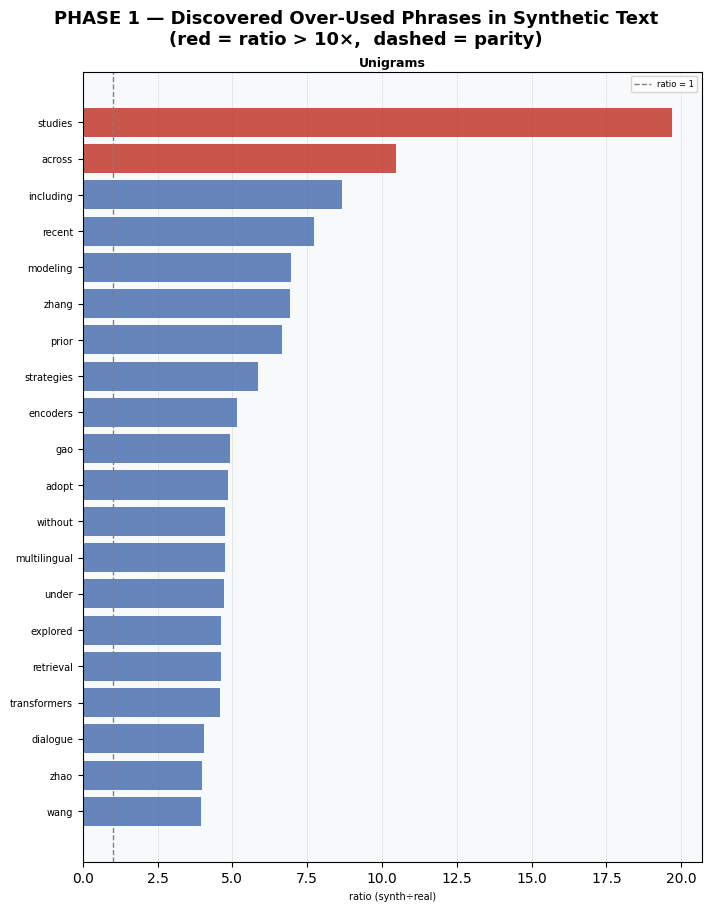

Saved → 01a_discovery_unigrams.png


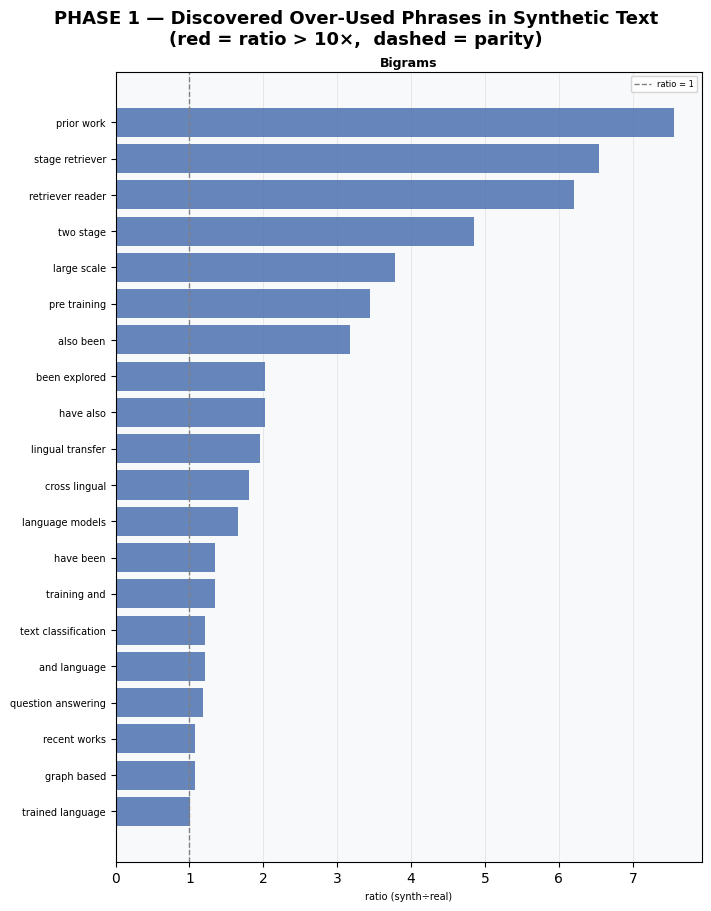

Saved → 01b_discovery_bigrams.png


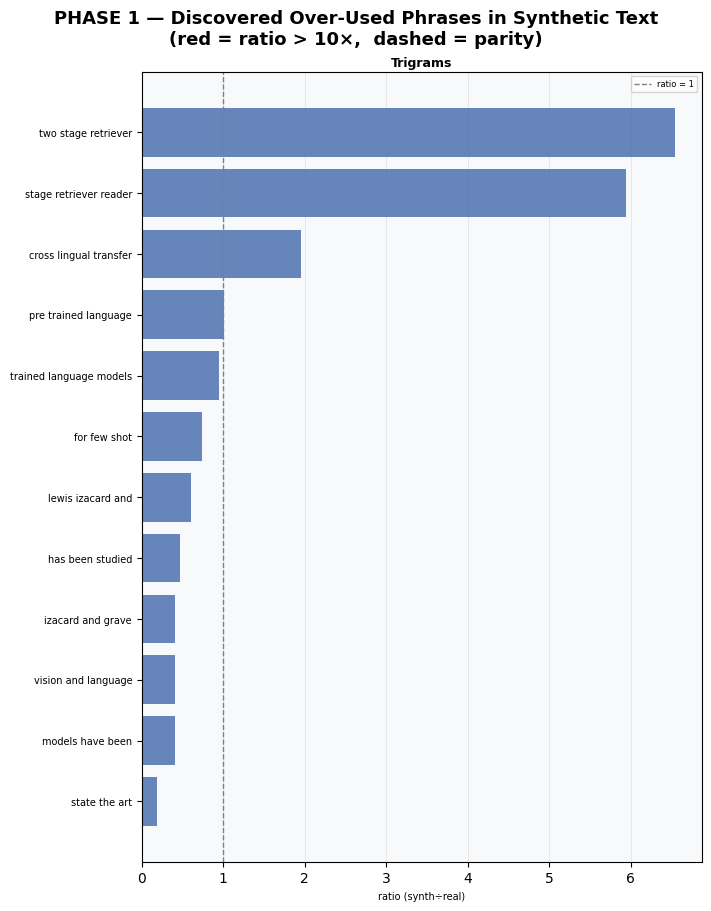

Saved → 01c_discovery_trigrams.png


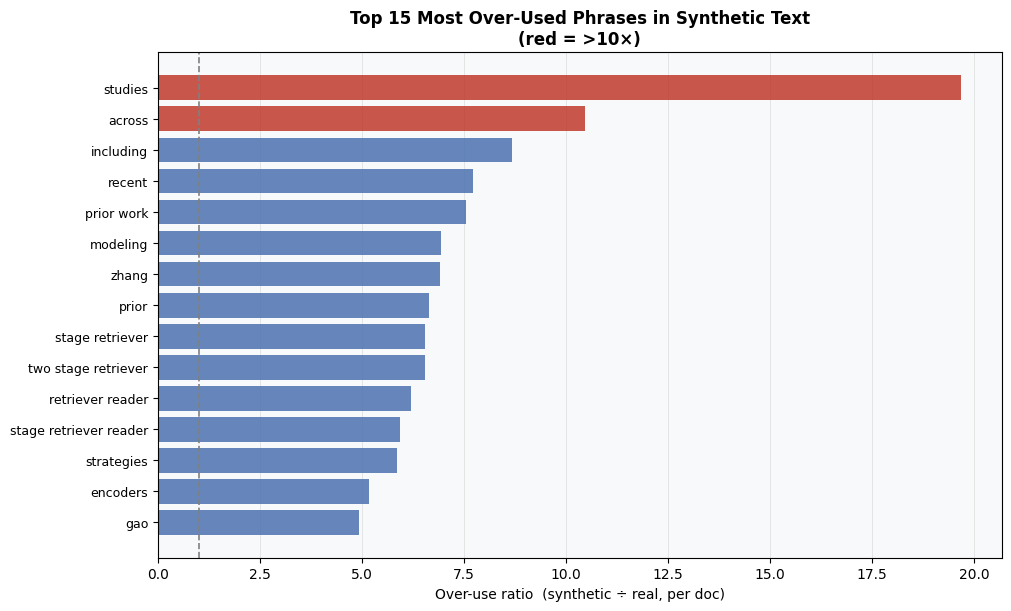

Saved → 03_top_overused_consolidated.png

  AUTO-DISCOVERED WATCHLISTS

  SCAFFOLD / FIXED PHRASES  (2- and 3-grams, ranked by ratio)
  Phrase                                    Real/doc  Synt/doc   Ratio
  ---------------------------------------- --------- --------- -------
  prior work                                 0.01070   0.08081    7.6x
  stage retriever                            0.01070   0.06999    6.5x
  retriever reader                           0.01070   0.06638    6.2x
  two stage                                  0.02139   0.10390    4.9x
  large scale                                0.01070   0.04040    3.8x
  pre training                               0.01070   0.03680    3.4x
  also been                                  0.01070   0.03391    3.2x
  been explored                              0.01070   0.02165    2.0x
  have also                                  0.01070   0.02165    2.0x
  lingual transfer                           0.01070   0.02092    2.0x
  cross lingua

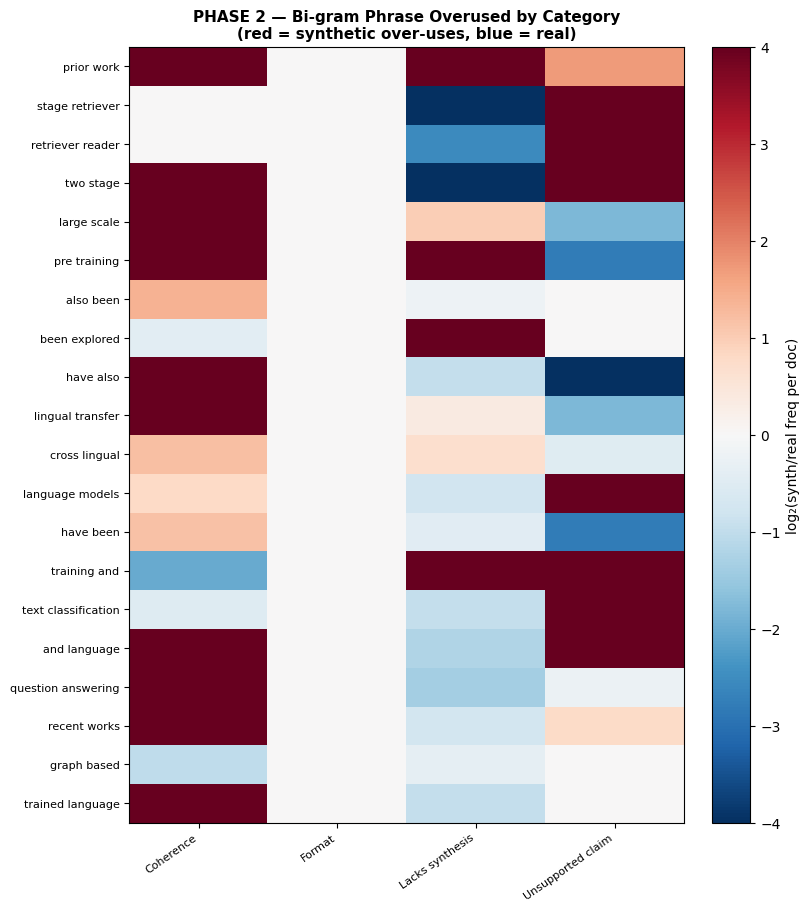

Saved → 02_scaffold_heatmap.png


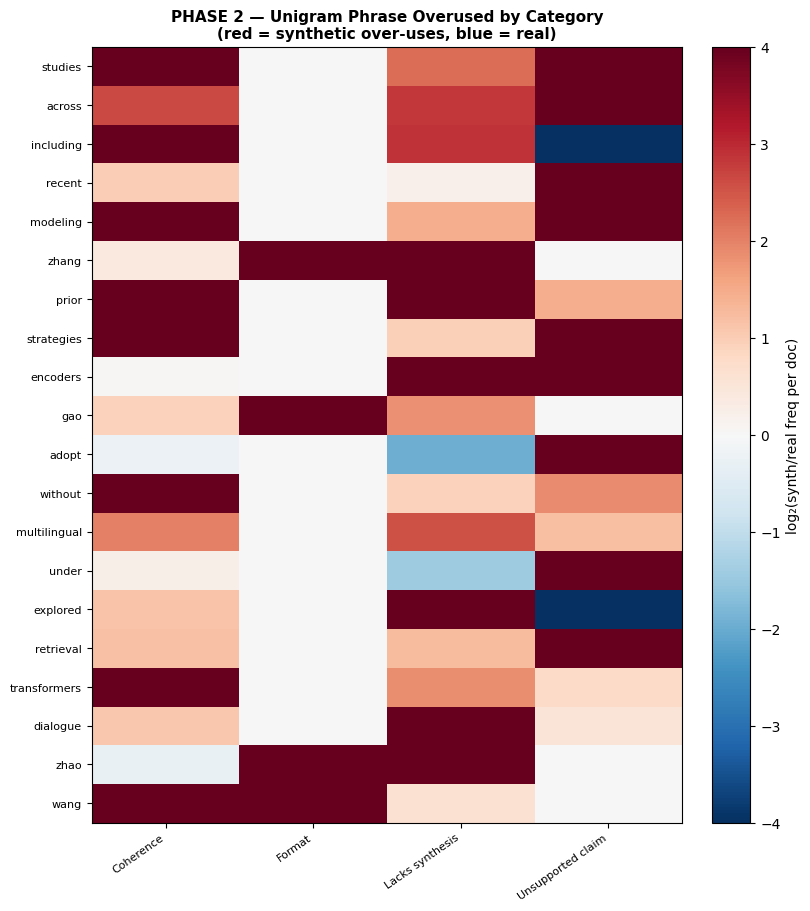

Saved → 02_transition_heatmap.png


In [28]:
import json
import numpy as np

np.random.seed(42)

synth_path = "../samples/synthetic_samples_complete.json"
real_path  = "../samples/total_real_data.json"

with open(synth_path, 'r') as f:
    synth_data = json.load(f)

with open(real_path, 'r') as f:
    real_data = json.load(f)

results = analyze_lexical_differences(
    real_data,
    synth_data,
    text_mode="span"
)